In [1]:
import sys
sys.path.append('./BIRM/Bayesian-Invariant-Risk-Minmization')
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix
from model import MLP as BaseMLP, EBD
from utils import *
from torch import optim, autograd
torch.manual_seed(0)
using_brain_features_only = True

from matplotlib import pyplot as plt

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
path_to_data = 'abide_thickness_cleaned.csv'
print(f'Using device: {device}')

Using device: mps


A fully connected NN as a benchmark

In [3]:
class TabularMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super(TabularMLP, self).__init__()
        self._main = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GroupNorm(8, hidden_dim),
            nn.PReLU(),
            nn.Dropout(0.2),  
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.GroupNorm(8, hidden_dim // 2),
            nn.PReLU(),
            nn.Dropout(0.2),  
            nn.Linear(hidden_dim // 2, 1)
        )
    
    def forward(self, x):
        return self._main(x)


wrapping the dataframe to comply with the original code

In [4]:
class TabularDataProvider(IRMDataProvider):
    def __init__(self, df, env_col, label_col, feature_cols, test_envs, device):
        super(TabularDataProvider, self).__init__(None)
        self.device = device
        train_mask = df[env_col].isin([e for e in df[env_col].unique() if e not in test_envs])
        scaler = StandardScaler()
        scaler.fit(df.loc[train_mask, feature_cols].values)
        features = scaler.transform(df[feature_cols].values)
        
        envs_unique = sorted(df[env_col].unique())
        self.envs = []
        for idx, env in enumerate(envs_unique):
            env_data = df[df[env_col] == env]
            env_features = torch.tensor(features[env_data.index], dtype=torch.float32).to(device)
            env_labels = torch.tensor(env_data[label_col].values, dtype=torch.float32).unsqueeze(1).to(device)
            env_g = torch.full((len(env_data),), idx, dtype=torch.long).to(device)
            env_c = torch.zeros(len(env_data), 1).to(device)
            self.envs.append({
                'images': env_features,
                'labels': env_labels,
                'color': env_c
            })
        # Reorder so test envs are last
        test_env_indices = [envs_unique.index(env) for env in test_envs if env in envs_unique]
        train_envs = [self.envs[i] for i in range(len(self.envs)) if i not in test_env_indices]
        test_envs_list = [self.envs[i] for i in test_env_indices]
        self.envs = train_envs + test_envs_list
        self.num_test = len(test_env_indices)
        self.preprocess_data()

    def preprocess_data(self):
        self.train_x, self.train_y, self.train_g, self.train_c = self.concat_envs_device(self.envs[:-self.num_test])
        self.test_x, self.test_y, self.test_g, self.test_c = self.concat_envs_device(self.envs[-self.num_test:])

    def concat_envs_device(self, con_envs):
        con_x = torch.cat([env["images"] for env in con_envs])
        con_y = torch.cat([env["labels"] for env in con_envs])
        con_g = torch.cat([
            ig * torch.ones_like(env["labels"])
            for ig,env in enumerate(con_envs)])
        con_c = torch.cat([env["color"] for env in con_envs])
        return con_x, con_y, con_g, con_c

Model for sampling for the posterior

In [5]:
class CustomEBD(nn.Module):
    def __init__(self, flags, device):
        super(CustomEBD, self).__init__()
        self.flags = flags
        self.device = device
        self.embedings = torch.nn.Embedding(flags.envs_num, 1).to(device)
        self.re_init()

    def re_init(self):
        self.embedings.weight.data.fill_(1.)

    def re_init_with_noise(self, noise_sd):
        rd = torch.normal(
            torch.Tensor([1.0] * self.flags.envs_num),
            torch.Tensor([noise_sd] * self.flags.envs_num))
        self.embedings.weight.data = rd.view(-1, 1).to(self.device)

    def forward(self, e):
        return self.embedings(e.long())

- converting categorical columns to numerics
- assigning 1 to ASD and 0 to Control

In [6]:
df = pd.read_csv(path_to_data)
print(f'Initial shape: {df.shape}')
df = df.dropna(axis=1)
print(f'After dropna: {df.shape}')

env_col = 'SITE_ID'
label_col = 'DX_LABEL'
feature_cols = [col for col in df.columns if col not in [env_col, label_col,'SUB_ID','FILE_ID','DX_GROUP']]

brain_features = [col for col in df.columns if col.startswith('lh_') or col.startswith('rh_')]
if using_brain_features_only:
    feature_cols = brain_features

for col in feature_cols+[env_col]:
    if df[col].dtype == 'object':
        print(f'Factorizing column: {col}')
        factors = pd.factorize(df[col])
        df[col] = factors[0]
        print(f'Unique values in {col}: {list(enumerate(factors[1].tolist()))}')

df[label_col] = df[label_col].map({'Control': 0, 'ASD': 1}) 
print(f'Labels before mapping: {df[label_col].unique()}')
df = df.dropna(subset=[label_col])
print(f'Labels after mapping and dropna: {df[label_col].value_counts()}')

Initial shape: (1027, 83)
After dropna: (1027, 81)
Factorizing column: SITE_ID
Unique values in SITE_ID: [(0, 'PITT'), (1, 'OLIN'), (2, 'OHSU'), (3, 'SDSU'), (4, 'TRINITY'), (5, 'UM_1'), (6, 'UM_2'), (7, 'USM'), (8, 'YALE'), (9, 'CMU'), (10, 'LEUVEN_1'), (11, 'LEUVEN_2'), (12, 'KKI'), (13, 'NYU'), (14, 'STANFORD'), (15, 'UCLA_1'), (16, 'UCLA_2'), (17, 'MAX_MUN'), (18, 'CALTECH'), (19, 'SBL')]
Labels before mapping: [1 0]
Labels after mapping and dropna: DX_LABEL
0    528
1    499
Name: count, dtype: int64


two sites sperated to be used as the test set

In [7]:
test_envs = [15, # UCLA_1
             5, # UM_1
             ]
dp = TabularDataProvider(df, env_col, label_col, feature_cols, test_envs, device)
input_dim = len(feature_cols)
mlp = TabularMLP(input_dim).to(device)
ebd = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)

the training procedure based on the original code (AI generated)

In [8]:
def train_model_fixed(mlp, ebd, dp, irm_type='birm',
                      steps=2000, lr=4e-4,
                      penalty_weight=1e4,
                      penalty_anneal_iters=200,
                      sampleN=15,
                      prior_sd_coef=1.0,
                      verbose=True,
                      track_history=True):

    optimizer = optim.Adam(mlp.parameters(), lr=lr, weight_decay=1e-3)
    loss_history = {'total': [], 'nll': [], 'penalty': []}
    acc_history  = {'train': [], 'test': []}
    n_train_envs = len(dp.envs) - dp.num_test

    for step in range(steps):
        train_x, train_y, train_g, train_c = dp.fetch_train()
        train_logits = mlp(train_x)

        if irm_type == 'birm':
            ebd.re_init()
            clean_logits = ebd(train_g).view(-1, 1) * train_logits
            clean_nll = nn.functional.binary_cross_entropy_with_logits(clean_logits, train_y)
            train_penalty = torch.tensor(0.0, device=device)
            for _ in range(sampleN):
                ebd.re_init_with_noise(prior_sd_coef)
                train_logits_w = ebd(train_g).view(-1, 1) * train_logits
                noisy_nll = nn.functional.binary_cross_entropy_with_logits(train_logits_w, train_y)
                grad = autograd.grad(noisy_nll * n_train_envs,
                                     ebd.parameters(), create_graph=True)[0]
                train_penalty = train_penalty + (1 / sampleN) * torch.mean(grad ** 2)
            w = min(penalty_weight, (step / max(penalty_anneal_iters, 1)) ** 2 * penalty_weight)
            loss = clean_nll + w * train_penalty
            if step == penalty_anneal_iters and verbose:
                print(f"  *** Penalty active: nll={clean_nll.item():.4f}, "
                      f"nll_vs_random={clean_nll.item()/0.693:.3f}")

        elif irm_type == 'erm':
            clean_nll = nn.functional.binary_cross_entropy_with_logits(train_logits, train_y)
            train_penalty = torch.tensor(0.0, device=device)
            loss = clean_nll

        elif irm_type == 'vrex':
            env_losses = []
            for g in range(n_train_envs):
                env_mask = (train_g == g).squeeze()
                if env_mask.sum() == 0:
                    continue
                env_loss = nn.functional.binary_cross_entropy_with_logits(
                    train_logits[env_mask], train_y[env_mask])
                env_losses.append(env_loss)
            env_losses = torch.stack(env_losses)
            clean_nll = env_losses.mean()
            train_penalty = env_losses.var(unbiased=False)
            ramp = min(1.0, (step / max(penalty_anneal_iters, 1)) ** 2)
            loss = clean_nll + penalty_weight * ramp * train_penalty

        else:
            raise ValueError(f"Unknown irm_type {irm_type}")

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if verbose and step % 200 == 0:
            print(f"Step {step}: loss={loss.item():.4f}, "
                  f"nll={clean_nll.item():.4f}, "
                  f"penalty={train_penalty.item():.6f}")

        if track_history and step % 200 == 0:
            loss_history['total'].append(loss.item())
            loss_history['nll'].append(clean_nll.item())
            loss_history['penalty'].append(train_penalty.item())
            train_acc, _, _, _ = evaluate_model(mlp, ebd, dp, eval_on='train')
            test_acc,  _, _, _ = evaluate_model(mlp, ebd, dp, eval_on='test')
            acc_history['train'].append(train_acc)
            acc_history['test'].append(test_acc)

    return mlp, ebd, loss_history, acc_history

In [9]:
def evaluate_model(mlp, ebd, dp, irm_type='birm', eval_on='test'):
    if eval_on == 'test':
        test_x, test_y, test_g, test_c = dp.fetch_test()
    else:
        test_x, test_y, test_g, test_c = dp.train_x, dp.train_y, dp.train_g, dp.train_c
    
    mlp.eval()
    with torch.no_grad():
        test_logits = mlp(test_x)
        
    preds = (torch.sigmoid(test_logits) > 0.5).float()
    acc = (preds == test_y).float().mean().item()
    probs = torch.sigmoid(test_logits).cpu().numpy()
    labels = test_y.cpu().numpy()
    
    auc = roc_auc_score(labels, probs)
    tn, fp, fn, tp = confusion_matrix(labels, preds.cpu().numpy()).ravel()
    type1_error = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    type2_error = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    mlp.train()
    return acc, type1_error, type2_error, auc


Search for optimal hyperparameters for BIRM based on the test set

In [22]:
import itertools

penalty_weights   = [100, 200, 500]
anneal_iters_list = [800, 1200, 1500]
prior_sd_coefs    = [0.5, 1.0, 2.0]

results = []
loss_histories = {}
acc_histories = {}

for pw, ai, sd in itertools.product(penalty_weights, anneal_iters_list, prior_sd_coefs):
    torch.manual_seed(42)
    mlp_init = TabularMLP(input_dim).to(device)
    ebd_init = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs) - len(test_envs)})(), device)

    mlp_b, ebd_b, losses, accs = train_model_fixed(
        mlp_init, ebd_init, dp,
        irm_type='birm',
        steps=3000,
        lr=4e-4,
        penalty_weight=pw,
        penalty_anneal_iters=ai,
        sampleN=15,
        prior_sd_coef=sd,
        verbose=False,
        track_history=False
    )

    acc, t1, t2, auc = evaluate_model(mlp_b, ebd_b, dp, irm_type='birm', eval_on='test')
    result_dict = {'pw': pw, 'ai': ai, 'sd': sd, 'acc': acc, 't1': t1, 't2': t2, 'auc': auc}
    results.append(result_dict)
    loss_histories[(pw, ai, sd)] = losses
    acc_histories[(pw, ai, sd)] = accs
    print(f"pw={pw:4d} | anneal={ai:4d} | sd={sd:.1f} → AUC={auc:.3f} | Acc={acc:.3f} | T1={t1:.3f} | T2={t2:.3f}")

# ── Summary ──────────────────────────────────────────────────────────────────────
best = max(results, key=lambda r: r['auc'])
print(f"\nBest config: penalty_weight={best['pw']}, anneal_iters={best['ai']}, "
      f"prior_sd_coef={best['sd']:.1f}")
print(f"Best BIRM: AUC={best['auc']:.3f} | Acc={best['acc']:.3f} | "
      f"T1={best['t1']:.3f} | T2={best['t2']:.3f}")

# ── ERM Baseline (once, for comparison) ─────────────────────────────────────────
torch.manual_seed(42)
mlp_erm = TabularMLP(input_dim, hidden_dim=128).to(device)
ebd_erm = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs) - len(test_envs)})(), device)
mlp_erm, ebd_erm, loss_erm_gs, acc_erm_gs = train_model_fixed(mlp_erm, ebd_erm, dp, irm_type='erm',
                                      steps=3000, verbose=False)
acc_e, t1_e, t2_e, auc_e = evaluate_model(mlp_erm, ebd_erm, dp, irm_type='erm', eval_on='test')
print(f"ERM baseline: AUC={auc_e:.3f} | Acc={acc_e:.3f} | T1={t1_e:.3f} | T2={t2_e:.3f}")


pw= 100 | anneal= 800 | sd=0.5 → AUC=0.539 | Acc=0.483 | T1=0.000 | T2=1.000
pw= 100 | anneal= 800 | sd=1.0 → AUC=0.503 | Acc=0.477 | T1=0.012 | T2=1.000
pw= 100 | anneal= 800 | sd=2.0 → AUC=0.564 | Acc=0.517 | T1=0.988 | T2=0.011
pw= 100 | anneal=1200 | sd=0.5 → AUC=0.529 | Acc=0.483 | T1=0.000 | T2=1.000
pw= 100 | anneal=1200 | sd=1.0 → AUC=0.554 | Acc=0.512 | T1=0.892 | T2=0.112
pw= 100 | anneal=1200 | sd=2.0 → AUC=0.561 | Acc=0.535 | T1=0.940 | T2=0.022
pw= 100 | anneal=1500 | sd=0.5 → AUC=0.559 | Acc=0.541 | T1=0.337 | T2=0.573
pw= 100 | anneal=1500 | sd=1.0 → AUC=0.505 | Acc=0.483 | T1=0.000 | T2=1.000
pw= 100 | anneal=1500 | sd=2.0 → AUC=0.564 | Acc=0.523 | T1=0.952 | T2=0.034
pw= 200 | anneal= 800 | sd=0.5 → AUC=0.480 | Acc=0.477 | T1=0.012 | T2=1.000
pw= 200 | anneal= 800 | sd=1.0 → AUC=0.564 | Acc=0.517 | T1=1.000 | T2=0.000
pw= 200 | anneal= 800 | sd=2.0 → AUC=0.565 | Acc=0.517 | T1=1.000 | T2=0.000
pw= 200 | anneal=1200 | sd=0.5 → AUC=0.491 | Acc=0.483 | T1=0.000 | T2=1.000

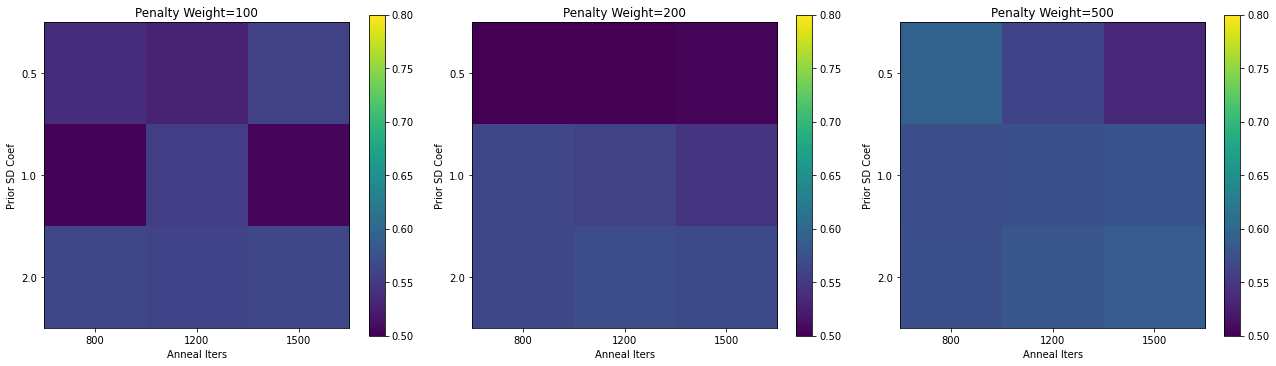

In [23]:

_, axs = plt.subplots(1, len(penalty_weights), figsize=(18, 5))
for i, pw in enumerate(penalty_weights):
    heatmap_data = np.zeros((len(prior_sd_coefs), len(anneal_iters_list)))
    for j, ai in enumerate(anneal_iters_list):
        for k, sd in enumerate(prior_sd_coefs):
            auc_val = next(r['auc'] for r in results if r['pw'] == pw and r['ai'] == ai and r['sd'] == sd)
            heatmap_data[k, j] = auc_val
    im = axs[i].imshow(heatmap_data, vmin=0.5, vmax=0.8, cmap='viridis')
    axs[i].set_title(f'Penalty Weight={pw}')
    axs[i].set_xticks(range(len(anneal_iters_list)))
    axs[i].set_xticklabels(anneal_iters_list)
    axs[i].set_yticks(range(len(prior_sd_coefs)))
    axs[i].set_yticklabels(prior_sd_coefs)
    axs[i].set_xlabel('Anneal Iters')
    axs[i].set_ylabel('Prior SD Coef')
    plt.colorbar(im, ax=axs[i])
plt.tight_layout()
plt.show()


From the heatmaps, sd=2 is actually better than .5 in general and I only sample one training per hyperparameter set so... I go with
penalty_weight=500, anneal_iters=800, prior_sd_coef=2.0

In [18]:
best_aucs = []
erm_aucs = []
best_losses_all_seeds = []
erm_losses_all_seeds = []
best_accs_all_seeds = []
erm_accs_all_seeds = []

for seed in range(10):
    torch.manual_seed(seed)
    
    mlp_b = TabularMLP(input_dim, hidden_dim=128).to(device)
    ebd_b = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)
    mlp_b, ebd_b, losses_b, accs_b = train_model_fixed(
        mlp_b, ebd_b, dp,
        irm_type='birm',
        steps=3000, lr=4e-4,
        penalty_weight=500,
        penalty_anneal_iters=800,
        sampleN=15,
        prior_sd_coef=2.0,
        verbose=False,
        track_history=False
    )
    _, _, _, auc_b = evaluate_model(mlp_b, ebd_b, dp, irm_type='birm', eval_on='test')
    best_aucs.append(auc_b)
    best_losses_all_seeds.append(losses_b)
    best_accs_all_seeds.append(accs_b)

    torch.manual_seed(seed)
    mlp_e = TabularMLP(input_dim).to(device)
    ebd_e = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)
    mlp_e, ebd_e, losses_e, accs_e = train_model_fixed(mlp_e, ebd_e, dp, irm_type='erm',
                                      steps=3000, verbose=False, track_history=False)
    _, _, _, auc_e = evaluate_model(mlp_e, ebd_e, dp, irm_type='erm', eval_on='test')
    erm_aucs.append(auc_e)
    erm_losses_all_seeds.append(losses_e)
    erm_accs_all_seeds.append(accs_e)
    
    print(f"Seed {seed:2d}: BIRM={auc_b:.3f}  ERM={auc_e:.3f}  Δ={auc_b-auc_e:+.3f}")

print(f"\nBIRM: {np.mean(best_aucs):.3f} ± {np.std(best_aucs):.3f}")
print(f"ERM:  {np.mean(erm_aucs):.3f} ± {np.std(erm_aucs):.3f}")
print(f"Mean gap: {np.mean(np.array(best_aucs)-np.array(erm_aucs)):+.3f}")


Seed  0: BIRM=0.596  ERM=0.621  Δ=-0.025
Seed  1: BIRM=0.514  ERM=0.575  Δ=-0.061
Seed  2: BIRM=0.566  ERM=0.628  Δ=-0.062
Seed  3: BIRM=0.509  ERM=0.580  Δ=-0.072
Seed  4: BIRM=0.586  ERM=0.629  Δ=-0.043
Seed  5: BIRM=0.509  ERM=0.575  Δ=-0.066
Seed  6: BIRM=0.531  ERM=0.606  Δ=-0.076
Seed  7: BIRM=0.475  ERM=0.636  Δ=-0.161
Seed  8: BIRM=0.574  ERM=0.631  Δ=-0.058
Seed  9: BIRM=0.527  ERM=0.604  Δ=-0.077

BIRM: 0.539 ± 0.038
ERM:  0.609 ± 0.023
Mean gap: -0.070


Evaluating Training Stability

In [24]:

print("Training BIRM...")
mlp_birm_init = TabularMLP(input_dim).to(device)
ebd_birm_init = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)

mlp_birm, ebd_birm, loss_birm, acc_birm = train_model_fixed(
    mlp_birm_init, ebd_birm_init, dp,
    irm_type='birm',
    lr=4e-4,
    penalty_weight=200,
    penalty_anneal_iters=500,
    sampleN=15,
    prior_sd_coef=1.0
)

print("\nTraining ERM...")
mlp_erm_init = TabularMLP(input_dim).to(device)
ebd_erm_init = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)

mlp_erm, ebd_erm, loss_erm, acc_erm = train_model_fixed(
    mlp_erm_init, ebd_erm_init, dp,
    irm_type='erm'
)


print("\nTraining V-REx...")
mlp_vrex_init = TabularMLP(input_dim).to(device)
ebd_vrex_init = CustomEBD(type('Flags', (), {'envs_num': len(dp.envs)-len(test_envs)})(), device)

mlp_vrex, ebd_vrex, loss_vrex, acc_vrex = train_model_fixed(
    mlp_vrex_init, ebd_vrex_init, dp,
    irm_type='vrex',
    steps=2000,
    lr=4e-4,
    penalty_weight=1.0,
    verbose=True
)


acc_birm_final, t1_birm, t2_birm, auc_birm = evaluate_model(mlp_birm, ebd_birm, dp, 'birm', eval_on='test')
acc_erm_final, t1_erm, t2_erm, auc_erm = evaluate_model(mlp_erm, ebd_erm, dp, 'erm', eval_on='test')
acc_vrex_final, t1_vrex, t2_vrex, auc_vrex = evaluate_model(mlp_vrex, ebd_vrex, dp, 'vrex', eval_on='test')

print(f'\nBIRM: Acc={acc_birm_final:.3f}, Type1={t1_birm:.3f}, Type2={t2_birm:.3f}, AUC={auc_birm:.3f}')
print(f'ERM:  Acc={acc_erm_final:.3f}, Type1={t1_erm:.3f}, Type2={t2_erm:.3f}, AUC={auc_erm:.3f}')
print(f'V-REx: Acc={acc_vrex_final:.3f}, Type1={t1_vrex:.3f}, Type2={t2_vrex:.3f}, AUC={auc_vrex:.3f}')


Training BIRM...
Step 0: loss=0.7277, nll=0.7277, penalty=0.008373
Step 200: loss=0.6911, nll=0.6733, penalty=0.000557
Step 400: loss=0.6933, nll=0.6880, penalty=0.000041
  *** Penalty active: nll=0.6893, nll_vs_random=0.995
Step 600: loss=0.6931, nll=0.6910, penalty=0.000010
Step 800: loss=0.6924, nll=0.6910, penalty=0.000007
Step 1000: loss=0.6921, nll=0.6904, penalty=0.000009
Step 1200: loss=0.6923, nll=0.6906, penalty=0.000008
Step 1400: loss=0.6919, nll=0.6906, penalty=0.000006
Step 1600: loss=0.6923, nll=0.6906, penalty=0.000008
Step 1800: loss=0.6918, nll=0.6903, penalty=0.000007

Training ERM...
Step 0: loss=0.7041, nll=0.7041, penalty=0.000000
Step 200: loss=0.4766, nll=0.4766, penalty=0.000000
Step 400: loss=0.2505, nll=0.2505, penalty=0.000000
Step 600: loss=0.1576, nll=0.1576, penalty=0.000000
Step 800: loss=0.0899, nll=0.0899, penalty=0.000000
Step 1000: loss=0.0896, nll=0.0896, penalty=0.000000
Step 1200: loss=0.0607, nll=0.0607, penalty=0.000000
Step 1400: loss=0.0450, n

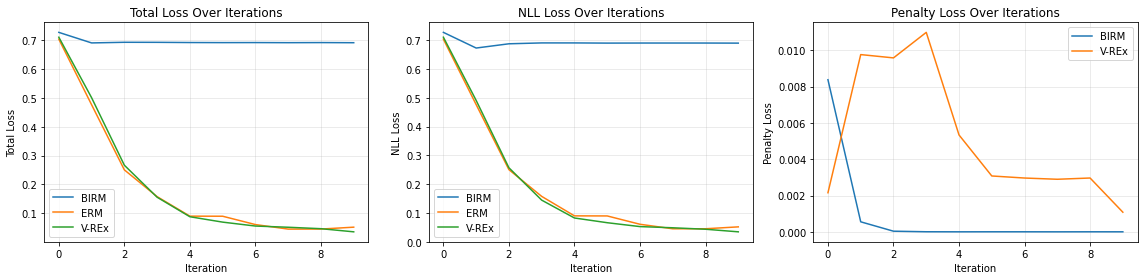

In [25]:
import matplotlib.pyplot as plt

# Plot loss curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Total Loss
axes[0].plot(loss_birm['total'], label='BIRM', linewidth=1.5)
axes[0].plot(loss_erm['total'], label='ERM', linewidth=1.5)
axes[0].plot(loss_vrex['total'], label='V-REx', linewidth=1.5)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Total Loss')
axes[0].set_title('Total Loss Over Iterations')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# NLL Loss
axes[1].plot(loss_birm['nll'], label='BIRM', linewidth=1.5)
axes[1].plot(loss_erm['nll'], label='ERM', linewidth=1.5)
axes[1].plot(loss_vrex['nll'], label='V-REx', linewidth=1.5)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('NLL Loss')
axes[1].set_title('NLL Loss Over Iterations')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Penalty
axes[2].plot(loss_birm['penalty'], label='BIRM', linewidth=1.5)
axes[2].plot(loss_vrex['penalty'], label='V-REx', linewidth=1.5)
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Penalty Loss')
axes[2].set_title('Penalty Loss Over Iterations')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


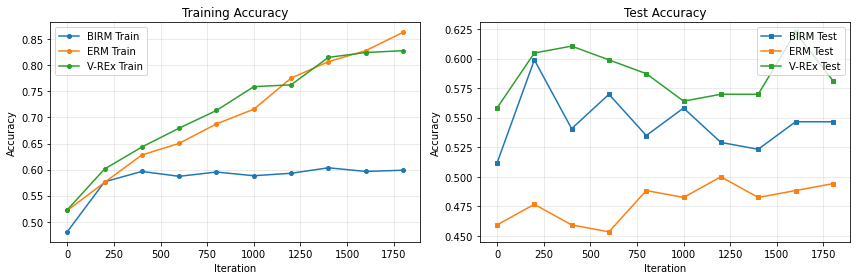

In [ ]:
# Plot training and test accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

steps = np.array(range(len(acc_birm['train']))) * 200

# Training accuracy
axes[0].plot(steps, acc_birm['train'], label='BIRM Train', linewidth=1.5, marker='o', markersize=4)
axes[0].plot(steps, acc_erm['train'], label='ERM Train', linewidth=1.5, marker='o', markersize=4)
axes[0].plot(steps, acc_vrex['train'], label='V-REx Train', linewidth=1.5, marker='o', markersize=4)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Training Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Test accuracy
axes[1].plot(steps, acc_birm['test'], label='BIRM Test', linewidth=1.5, marker='s', markersize=4)
axes[1].plot(steps, acc_erm['test'], label='ERM Test', linewidth=1.5, marker='s', markersize=4)
axes[1].plot(steps, acc_vrex['test'], label='V-REx Test', linewidth=1.5, marker='s', markersize=4)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### comparison across multiple initializations

In [26]:



N_SEEDS = 10
CONFIGS = {
    'BIRM': dict(irm_type='birm', steps=2000, lr=4e-4,
                 penalty_weight=200, penalty_anneal_iters=500,
                 sampleN=15, prior_sd_coef=0.5),
    'ERM':  dict(irm_type='erm',  steps=2000, lr=4e-4,
                 penalty_weight=0),
    'VREx': dict(irm_type='vrex', steps=2000, lr=4e-4,
                 penalty_weight=1.0, penalty_anneal_iters=300),
}
COLORS = {'BIRM': 'tab:blue', 'ERM': 'tab:orange', 'VREx': 'tab:green'}


results   = {k: [] for k in CONFIGS}   
test_curves = {k: [] for k in CONFIGS} 

for seed in range(N_SEEDS):
    print(f"\n── Seed {seed} ──")
    for name, cfg in CONFIGS.items():
        torch.manual_seed(seed)
        mlp_ = TabularMLP(input_dim, hidden_dim=64).to(device)
        ebd_ = CustomEBD(
            type('Flags', (), {'envs_num': len(dp.envs) - len(test_envs)})(),
            device)

        mlp_, ebd_, _, accs = train_model_fixed(
            mlp_, ebd_, dp, verbose=False, **cfg)

        _, _, _, auc = evaluate_model(mlp_, ebd_, dp, eval_on='test')
        results[name].append(auc)
        test_curves[name].append(accs['test'])
        print(f"  {name:5s}: AUC={auc:.3f}")

print("\n── Final AUC (mean ± std over 10 seeds) ──")
for name in CONFIGS:
    aucs = results[name]
    print(f"  {name:5s}: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}  "
          f"[min={min(aucs):.3f}, max={max(aucs):.3f}]")



── Seed 0 ──
  BIRM : AUC=0.520
  ERM  : AUC=0.626
  VREx : AUC=0.607

── Seed 1 ──
  BIRM : AUC=0.496
  ERM  : AUC=0.621
  VREx : AUC=0.613

── Seed 2 ──
  BIRM : AUC=0.572
  ERM  : AUC=0.601
  VREx : AUC=0.579

── Seed 3 ──
  BIRM : AUC=0.521
  ERM  : AUC=0.588
  VREx : AUC=0.604

── Seed 4 ──
  BIRM : AUC=0.501
  ERM  : AUC=0.641
  VREx : AUC=0.606

── Seed 5 ──
  BIRM : AUC=0.500
  ERM  : AUC=0.655
  VREx : AUC=0.641

── Seed 6 ──
  BIRM : AUC=0.523
  ERM  : AUC=0.607
  VREx : AUC=0.580

── Seed 7 ──
  BIRM : AUC=0.579
  ERM  : AUC=0.579
  VREx : AUC=0.557

── Seed 8 ──
  BIRM : AUC=0.440
  ERM  : AUC=0.603
  VREx : AUC=0.588

── Seed 9 ──
  BIRM : AUC=0.541
  ERM  : AUC=0.565
  VREx : AUC=0.597

── Final AUC (mean ± std over 10 seeds) ──
  BIRM : 0.519 ± 0.038  [min=0.440, max=0.579]
  ERM  : 0.609 ± 0.026  [min=0.565, max=0.655]
  VREx : 0.597 ± 0.022  [min=0.557, max=0.641]


[Text(0, 0, 'BIRM'), Text(1, 0, 'ERM'), Text(2, 0, 'VREx')]

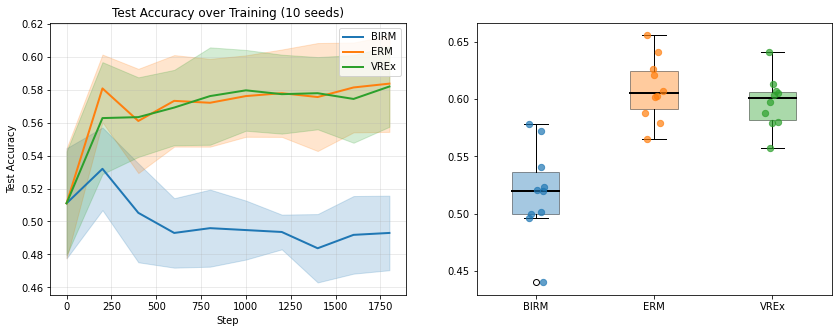

In [27]:
from matplotlib import pyplot as plt

steps_axis = np.arange(len(test_curves['ERM'][0])) * 200

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


for name, color in COLORS.items():
    arr = np.array(test_curves[name])  
    mean, std = arr.mean(0), arr.std(0) 
    axes[0].plot(steps_axis, mean, label=name, color=color, linewidth=2)
    axes[0].fill_between(steps_axis, mean - std, mean + std,
                         alpha=0.2, color=color)
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title(f'Test Accuracy over Training ({N_SEEDS} seeds)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)


positions = np.arange(len(CONFIGS))
for i, (name, color) in enumerate(COLORS.items()):
    aucs = results[name]
    axes[1].boxplot(aucs, positions=[i], widths=0.4,
                    patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.4),
                    medianprops=dict(color='black', linewidth=2))
    axes[1].scatter(np.full(len(aucs), i) + np.random.uniform(-0.08, 0.08, len(aucs)),
                    aucs, color=color, alpha=0.7, zorder=3, s=40)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CONFIGS.keys())

### Testing Ensamble Models

In [ ]:

N_SEEDS = 10

ENSEMBLE_CONFIGS = {
    'BIRM': dict(irm_type='birm', steps=2000, lr=4e-4,
                 penalty_weight=200, penalty_anneal_iters=1500,
                 sampleN=15, prior_sd_coef=0.5),
    'ERM':  dict(irm_type='erm',  steps=2000, lr=4e-4),
    'VREx': dict(irm_type='vrex', steps=1500, lr=4e-4,
                 penalty_weight=1.0, penalty_anneal_iters=300),
}

test_x, test_y, _, _ = dp.fetch_test()
labels = test_y.cpu().numpy()

ensemble_results = {}

for name, cfg in ENSEMBLE_CONFIGS.items():
    print(f"\nTraining {name} ensemble ({N_SEEDS} seeds)...")
    probs_all = []

    for seed in range(N_SEEDS):
        torch.manual_seed(seed)
        mlp_ = TabularMLP(input_dim, hidden_dim=64).to(device)
        ebd_ = CustomEBD(
            type('Flags', (), {'envs_num': len(dp.envs) - len(test_envs)})(),
            device)

        mlp_, ebd_, _, _ = train_model_fixed(
            mlp_, ebd_, dp, verbose=False, track_history=False, **cfg)

        mlp_.eval()
        with torch.no_grad():
            p = torch.sigmoid(mlp_(test_x)).cpu().numpy()
        probs_all.append(p)
        print(f"  seed {seed}: individual AUC={roc_auc_score(labels, p):.3f}")

    ensemble_probs = np.mean(probs_all, axis=0)
    ensemble_auc = roc_auc_score(labels, ensemble_probs)
    ensemble_results[name] = {
        'probs': ensemble_probs,
        'auc': ensemble_auc,
        'individual_aucs': [roc_auc_score(labels, p) for p in probs_all]
    }
    indiv = ensemble_results[name]['individual_aucs']
    print(f"  {name} individual: {np.mean(indiv):.3f} ± {np.std(indiv):.3f}")
    print(f"  {name} ENSEMBLE:   {ensemble_auc:.3f}")


print("\n── Ensemble AUC Summary ──")
for name, res in ensemble_results.items():
    indiv = res['individual_aucs']
    print(f"  {name:5s}: ensemble={res['auc']:.3f} | "
          f"individual mean={np.mean(indiv):.3f} ± {np.std(indiv):.3f}")




Training BIRM ensemble (10 seeds)...
  seed 0: individual AUC=0.498
  seed 1: individual AUC=0.495
  seed 2: individual AUC=0.479
  seed 3: individual AUC=0.514
  seed 4: individual AUC=0.547
  seed 5: individual AUC=0.484
  seed 6: individual AUC=0.486
  seed 7: individual AUC=0.547
  seed 8: individual AUC=0.424
  seed 9: individual AUC=0.460
  BIRM individual: 0.493 ± 0.035
  BIRM ENSEMBLE:   0.499

Training ERM ensemble (10 seeds)...
  seed 0: individual AUC=0.626
  seed 1: individual AUC=0.621
  seed 2: individual AUC=0.601
  seed 3: individual AUC=0.588
  seed 4: individual AUC=0.641
  seed 5: individual AUC=0.655
  seed 6: individual AUC=0.607
  seed 7: individual AUC=0.579
  seed 8: individual AUC=0.603
  seed 9: individual AUC=0.565
  ERM individual: 0.609 ± 0.026
  ERM ENSEMBLE:   0.638

Training VREx ensemble (10 seeds)...
  seed 0: individual AUC=0.625
  seed 1: individual AUC=0.611
  seed 2: individual AUC=0.567
  seed 3: individual AUC=0.602
  seed 4: individual AUC=0.59

NameError: name 'colors' is not defined

AttributeError: module 'matplotlib.pyplot' has no attribute 'set_xticks'

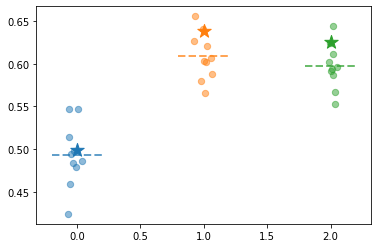

In [13]:



for i, (name, res) in enumerate(ensemble_results.items()):
    indiv = res['individual_aucs']
    color = COLORS[name]
    
    plt.scatter(np.full(N_SEEDS, i) + np.random.uniform(-0.08, 0.08, N_SEEDS),
                    indiv, color=color, alpha=0.5, s=40, zorder=3)
    
    plt.scatter(i, res['auc'], color=color, s=200, marker='*',
                    zorder=5, label=f"{name} ensemble={res['auc']:.3f}")
    
    plt.hlines(np.mean(indiv), i - 0.2, i + 0.2,
                   color=color, linewidth=2, linestyle='--', alpha=0.7)

plt.set_xticks(range(len(ENSEMBLE_CONFIGS)))
plt.set_xticklabels(ENSEMBLE_CONFIGS.keys())
plt.set_ylabel('AUC')
plt.set_title('Individual vs Ensemble AUC (★ = ensemble)')
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3, axis='y')



plt.show()